## Implementacija Thomasovog algoritma i numeričko rješavanje rubnog problema

Trodijagonalnu matricu
$$A=\begin{bmatrix} b_0 & c_0 & & & \\ a_0 & b_1 & c_1 & & \\ & \ddots & \ddots & \ddots & \\ & & a_{n-3} & b_{n-2} & c_{n-2}\\ & & & a_{n-2} & b_{n-1}\end{bmatrix}$$
pamtimo pomoću tri vektora $a=[a_0,\dots,a_{n-2}]$, $b=[b_0,\dots,b_{n-1}]$ i $c=[c_0,\dots,c_{n-2}]$, dakle umjesto $n^2$ elemenata pamtimo samo $3n-2$.

### Thomasov algoritam

Gaussova eliminacija bez pivotiranja na trodijagonalnoj matrici daje faktorizaciju $A=LU$. Matrica $L$ ima jedinice na dijagonali i multiplikatore $l_k$ ispod nje, a $U$ ima dijagonalu $u_k$ i istu gornju sporednu dijagonalu $c_k$ kao $A$:
$$u_0=b_0,\qquad l_k=\frac{a_{k-1}}{u_{k-1}},\qquad u_k=b_k-l_k\,c_{k-1},\qquad k=1,\dots,n-1.$$
Sustav $Ax=f$ zatim rješavamo u dva koraka, $Ly=f$ i $Ux=y$:
$$y_0=f_0,\quad y_k=f_k-l_k\,y_{k-1};\qquad x_{n-1}=\frac{y_{n-1}}{u_{n-1}},\quad x_k=\frac{y_k-c_k\,x_{k+1}}{u_k}.$$
Ukupno je to oko $8n$ računskih operacija, tj. složenost $O(n)$, za razliku od $O(n^3)$ za punu matricu.

**Stabilnost.** Algoritam ne pivotira, pa može pasti (pivot $u_k=0$) ili biti nestabilan zbog malog pivota (vidi zadatak 5 iz 1. laboratorijske vježbe). Stabilan je ako je matrica strogo dijagonalno dominantna, $|b_k|>|a_{k-1}|+|c_k|$, ili simetrična pozitivno definitna. Matrica rubnog problema koji rješavamo u nastavku je simetrična pozitivno definitna, pa pivotiranje nije potrebno.

In [1]:
import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt

In [2]:
def LUdecomptridiagonal(a,b,c):
    n=len(b)
    for k in range(1,n):
        mu=a[k-1]/b[k-1]
        b[k]=b[k]-mu*c[k-1]
        a[k-1]=mu
    return a,b,c

def LUsolvetridiagonal(a,b,c,f):
    n=len(b)
    for k in range(1,n):
        f[k]=f[k]-a[k-1]*f[k-1]
    f[n-1]=f[n-1]/b[n-1]
    for k in range(n-2,-1,-1):
        f[k]=(f[k]-c[k]*f[k+1])/b[k]
    return f

**Napomene uz implementaciju.**

- U kodu je multiplikator $l_k$ spremljen u `a[k-1]`, a pivot $u_k$ u `b[k]`. Petlja u `LUdecomptridiagonal` je doslovno formula $l_k=\frac{a_{k-1}}{u_{k-1}}$, $u_k=b_k-l_k\,c_{k-1}$.
- Funkcije rade **na mjestu** (*in place*): `LUdecomptridiagonal` prepisuje vektor `a` multiplikatorima $l_k$, a vektor `b` dijagonalom $u_k$ matrice $U$. Vektor `c` se ne mijenja, jer je gornja sporedna dijagonala od $U$ jednaka onoj od $A$. Faktorizacija tako ne treba dodatnu memoriju.
- `LUsolvetridiagonal` prepisuje vektor `f`: najprije rješenjem $y$ sustava $Ly=f$, a zatim rješenjem $x$ sustava $Ux=y$, koje i vraća.
- Posljedica: nakon poziva originalni `a`, `b` i `f` više nisu dostupni. Ako ih trebamo i kasnije (npr. za usporedbu ili provjeru reziduala), funkcijama predajemo kopije (`a.copy()` itd.).
- Vektori moraju biti realnog tipa (`float`); u cjelobrojnom nizu rezultati dijeljenja bi se odsijecali.

### Rubni problem

Rješavamo
$$-u''(x)=f(x),\quad x\in(0,1),\qquad u(0)=\alpha,\quad u(1)=\beta.$$
Na mreži $x_i=ih$, $i=0,\dots,n+1$, $h=\frac{1}{n+1}$, drugu derivaciju zamijenimo centralnom razlikom
$$u''(x_i)\approx\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}.$$
Za unutarnje čvorove $i=1,\dots,n$ dobivamo jednadžbe
$$-u_{i-1}+2u_i-u_{i+1}=h^2 f(x_i),$$
uz $u_0=\alpha$ i $u_{n+1}=\beta$. Poznate rubne vrijednosti prebacimo na desnu stranu, pa dobivamo trodijagonalni sustav
$$\begin{bmatrix}2&-1&&\\-1&2&\ddots&\\&\ddots&\ddots&-1\\&&-1&2\end{bmatrix}\begin{bmatrix}u_1\\u_2\\\vdots\\u_n\end{bmatrix}=\begin{bmatrix}h^2f(x_1)+\alpha\\h^2f(x_2)\\\vdots\\h^2f(x_n)+\beta\end{bmatrix}.$$
Desna strana je pomnožena s $h^2$, pa matrica nema faktor $1/h^2$.

U primjeru je $f(x)=16\pi^2\sin(4\pi x)$ i $\alpha=\beta=0$, a egzaktno rješenje je $u(x)=\sin(4\pi x)$.

In [3]:
def RHS_b(x):
    return 16.0*np.pi*np.pi*np.sin(4.0*np.pi*x)

def Exact_solution(x):
    return np.sin(4.0*np.pi*x)

def  set_abcf(x, alpha, beta):
    n=len(x)-2
    h=1.0/(n+1)
    f=np.ones((n))*h*h
    b=np.ones((n))*2.0
    a=np.ones((n-1))*(-1)
    c=np.ones((n-1))*(-1)
    for i in range(1,n+1):
        f[i-1]=f[i-1]*RHS_b(x[i])
    f[0]=f[0]+alpha
    f[n-1]=f[n-1]+ beta
    return a, b, c, f

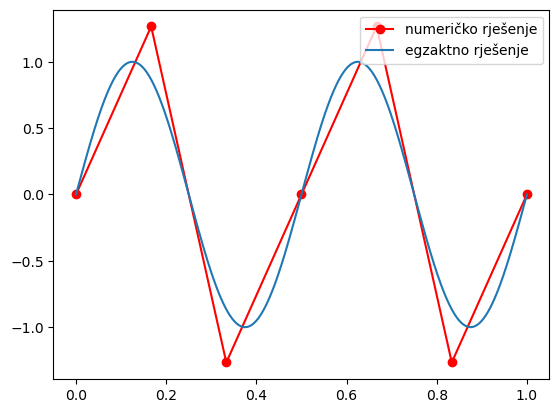

In [4]:
n1=5                                  # broj unutarnjih čvorova
x1=np.linspace(0,1,n1+2)              # mreža s rubovima
a,b,c,f=set_abcf(x1,0,0)
a,b,c=LUdecomptridiagonal(a,b,c)
u=LUsolvetridiagonal(a,b,c,f)
u=np.concatenate(([0], u, [0]))       # dodamo rubne vrijednosti u(0)=0, u(1)=0
z1=np.linspace(0,1,1000)
plt.plot(x1,u, "ro-", label="numeričko rješenje")
plt.plot(z1, Exact_solution(z1), label="egzaktno rješenje")
plt.legend()
plt.show()

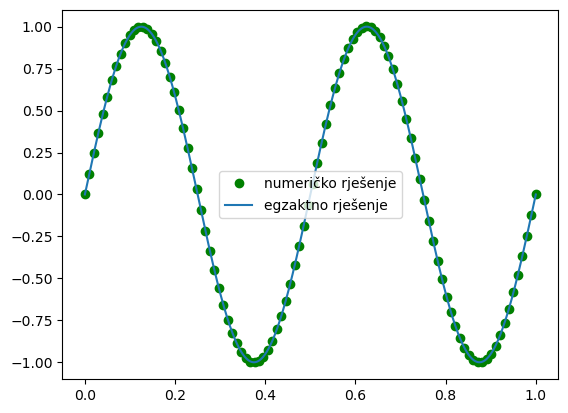

In [5]:
n3=100                                # broj unutarnjih čvorova
x3=np.linspace(0,1,n3+2)              # mreža s rubovima
a,b,c,f=set_abcf(x3,0,0)
a,b,c=LUdecomptridiagonal(a,b,c)
u=LUsolvetridiagonal(a,b,c,f)
u=np.concatenate(([0], u, [0]))       # dodamo rubne vrijednosti u(0)=0, u(1)=0
z1=np.linspace(0,1,1000)
plt.plot(x3,u, "go", label="numeričko rješenje")
plt.plot(z1, Exact_solution(z1), label="egzaktno rješenje")
plt.legend()
plt.show()

### Greška i red konvergencije

Centralna razlika ima grešku $O(h^2)$, pa bi se udvostručenjem broja čvorova greška trebala smanjiti oko 4 puta. Mjerimo najveću grešku u čvorovima, $\max_i |u_i-u(x_i)|$.

In [6]:
print(f"{'n':>8} | {'h':>8} | {'max greška':>11} | {'omjer':>6}")
prev=None
for n in [10, 20, 40, 80, 160, 320, 640, 10**4, 10**5, 10**6]:
    x=np.linspace(0,1,n+2)
    a,b,c,f=set_abcf(x,0,0)
    a,b,c=LUdecomptridiagonal(a,b,c)
    u=LUsolvetridiagonal(a,b,c,f)
    err=np.max(np.abs(u-Exact_solution(x[1:n+1])))
    ratio = f"{prev/err:6.2f}" if prev is not None and n <= 640 else ""
    print(f"{n:8d} | {1/(n+1):8.1e} | {err:11.3e} | {ratio:>6}")
    prev=err

       n |        h |  max greška |  omjer
      10 |  9.1e-02 |   1.151e-01 |       
      20 |  4.8e-02 |   3.030e-02 |   3.80
      40 |  2.4e-02 |   7.859e-03 |   3.85
      80 |  1.2e-02 |   2.008e-03 |   3.91
     160 |  6.2e-03 |   5.078e-04 |   3.95
     320 |  3.1e-03 |   1.277e-04 |   3.98
     640 |  1.6e-03 |   3.203e-05 |   3.99
   10000 |  1.0e-04 |   1.316e-07 |       
  100000 |  1.0e-05 |   1.637e-09 |       
 1000000 |  1.0e-06 |   3.299e-07 |       


  100000 |  1.0e-05 |   1.637e-09 |       


 1000000 |  1.0e-06 |   3.299e-07 |       


Omjer uzastopnih grešaka teži 4, što potvrđuje red konvergencije $O(h^2)$.

Za vrlo male $h$ greška ponovno **raste**: najmanja je oko $1.6\cdot 10^{-9}$ za $h=10^{-5}$, a za $h=10^{-6}$ iznosi $3.3\cdot 10^{-7}$. Diskretizacijska greška $\sim Ch^2$ i dalje pada, ali raste utjecaj grešaka zaokruživanja. Zato postoji optimalni korak $h$, a profinjavanje mreže iza njega ne poboljšava rješenje.

### Zadatak

1. Riješite rubni problem s drugom desnom stranom i poznatim egzaktnim rješenjem, npr. $u(x)=e^x$, za koji je $f(x)=-e^x$, $\alpha=1$, $\beta=e$. Promijenite funkcije `RHS_b` i `Exact_solution` te funkciju `set_abcf` pozovite s rubnim vrijednostima $\alpha$ i $\beta$.
2. Grafički usporedite numeričko i egzaktno rješenje za nekoliko vrijednosti $n$.
3. Izračunajte tablicu grešaka kao gore i provjerite red konvergencije.